# 💳 Phase 04: Exploratory Data Analysis (EDA) — Credit Card Fraud Detection
**Project:** AI-Powered Transaction Risk Scoring System  
**Objective:** Perform a rigorous, reproducible, end-to-end exploratory data analysis on the European Credit Card Fraud Detection dataset to identify distributions, class imbalance, outliers, feature correlations, and data quality issues that will inform Phase 5 Preprocessing and Feature Engineering.

---
### Notebook Outline
1. **Environment Setup & Imports**
2. **Dataset Ingestion & Dimensions**
3. **Data Inspection (Head & Tail)**
4. **Data Types, Missing Values & Duplicates Analysis**
5. **Statistical Summary & Distribution Profiling**
6. **Target Distribution & Class Imbalance Analysis**
7. **Temporal Analysis (`Time` Feature)**
8. **Monetary Analysis (`Amount` Feature)**
9. **PCA Features (`V1`–`V28`) Distribution & Outlier Profiling**
10. **Feature Correlation Analysis (with Fraud Target)**
11. **Comparative Analysis: Fraud vs. Legitimate Transactions**
12. **Data Leakage & Integrity Assessment**
13. **Summary of Findings & Recommendations for Phase 5**

In [1]:
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Suppress minor warnings for clean reporting
warnings.filterwarnings('ignore')

# Set aesthetic plot configurations
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12

print("Libraries loaded successfully.")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

Libraries loaded successfully.
Pandas version: 2.2.3
NumPy version: 2.2.2


## 1. Dataset Ingestion & Basic Properties

In [2]:
# Relative path from ml/notebooks/ to ml/data/raw/
DATA_PATH = Path("../data/raw/creditcard.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at {DATA_PATH.resolve()}. Ensure Phase 4 download was completed.")

df = pd.read_csv(DATA_PATH)

print(f"Dataset successfully loaded from: {DATA_PATH}")
print(f"Total Rows (Transactions): {df.shape[0]:,}")
print(f"Total Columns (Features + Target): {df.shape[1]}")
print(f"Memory Usage: {df.memory_usage(deep=True).sum() / (1024 * 1024):.2f} MB")

Dataset successfully loaded from: ..\data\raw\creditcard.csv
Total Rows (Transactions): 284,807
Total Columns (Features + Target): 31
Memory Usage: 67.36 MB


In [3]:
# Preview first 5 rows
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
# Preview last 5 rows
df.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


## 2. Data Types, Missing Values & Duplicate Records

In [5]:
# Summary of data types
dtype_counts = df.dtypes.value_counts()
print("Data Types Breakdown:")
print(dtype_counts)

# Missing values check
missing_counts = df.isnull().sum()
total_missing = missing_counts.sum()
print(f"\nTotal Missing Values across all columns: {total_missing}")

# Duplicates check
duplicate_rows = df.duplicated().sum()
print(f"Total Duplicate Rows: {duplicate_rows:,} ({(duplicate_rows / len(df)) * 100:.4f}% of total dataset)")

Data Types Breakdown:
float64    30
int64       1
Name: count, dtype: int64

Total Missing Values across all columns: 0


Total Duplicate Rows: 1,081 (0.3796% of total dataset)


In [6]:
# Duplicate distribution by class
dup_df = df[df.duplicated(keep=False)]
print("Duplicate breakdown by Class:")
print(dup_df['Class'].value_counts())
print("\nObservation: There are duplicate records in both legitimate and fraudulent transactions.")
print("Recommendation: Investigate during Phase 5 whether duplicate transactions represent re-tries/replay attacks or duplicate logging.")

Duplicate breakdown by Class:
Class
0    1822
1      32
Name: count, dtype: int64

Observation: There are duplicate records in both legitimate and fraudulent transactions.
Recommendation: Investigate during Phase 5 whether duplicate transactions represent re-tries/replay attacks or duplicate logging.


## 3. Comprehensive Statistical Summary

In [7]:
# Summary statistics for non-PCA columns: Time and Amount
df[['Time', 'Amount']].describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16


In [8]:
# Summary statistics for PCA features (V1 through V28)
df[[f'V{i}' for i in range(1, 29)]].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]

,mean,std,min,25%,50%,75%,max
V1,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995
V10,2.239053e-15,1.088850,-24.588262,-0.535426,-0.092917,0.453923,23.745136


## 4. Target Distribution & Class Imbalance Analysis

In [9]:
# Calculate target counts and proportions
class_counts = df['Class'].value_counts()
class_pcts = df['Class'].value_counts(normalize=True) * 100

legit_count = class_counts[0]
fraud_count = class_counts[1]
imbalance_ratio = legit_count / fraud_count

print("=" * 50)
print("CLASS DISTRIBUTION SUMMARY")
print("=" * 50)
print(f"Legitimate Transactions (Class 0): {legit_count:,} ({class_pcts[0]:.4f}%)")
print(f"Fraudulent Transactions (Class 1): {fraud_count:,} ({class_pcts[1]:.4f}%)")
print(f"Total Transactions:                {len(df):,}")
print(f"Class Imbalance Ratio:             {imbalance_ratio:.2f} : 1 (1 fraud per ~{int(round(imbalance_ratio))} legitimate)")
print("=" * 50)

CLASS DISTRIBUTION SUMMARY
Legitimate Transactions (Class 0): 284,315 (99.8273%)
Fraudulent Transactions (Class 1): 492 (0.1727%)
Total Transactions:                284,807
Class Imbalance Ratio:             577.88 : 1 (1 fraud per ~578 legitimate)


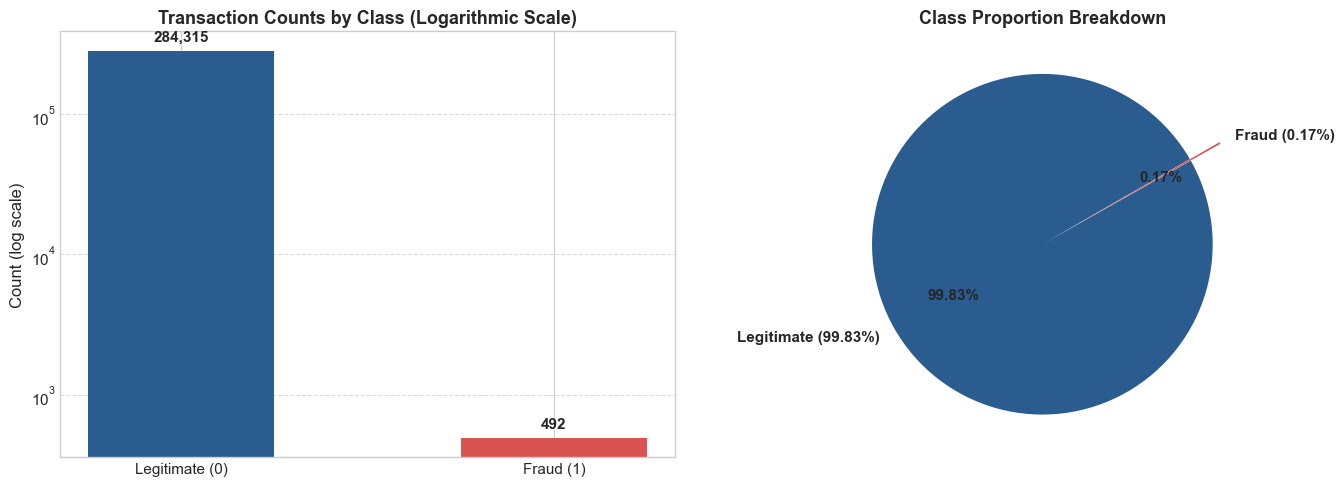

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Raw Counts (Log Scale)
bars = ax1.bar(['Legitimate (0)', 'Fraud (1)'], [legit_count, fraud_count], color=['#2b5c8f', '#d9534f'], width=0.5)
ax1.set_yscale('log')
ax1.set_title("Transaction Counts by Class (Logarithmic Scale)", fontweight='bold')
ax1.set_ylabel("Count (log scale)")
ax1.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    height = bar.get_height()
    ax1.annotate(f"{height:,}",
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 5), textcoords="offset points",
                 ha='center', va='bottom', fontweight='bold')

# Subplot 2: Proportions
wedges, texts, autotexts = ax2.pie([legit_count, fraud_count],
                                   labels=['Legitimate (99.83%)', 'Fraud (0.17%)'],
                                   colors=['#2b5c8f', '#d9534f'],
                                   explode=(0, 0.2),
                                   autopct='%1.2f%%',
                                   startangle=30,
                                   textprops=dict(fontweight='bold'))
ax2.set_title("Class Proportion Breakdown", fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Temporal Feature Analysis (`Time`)

Total time span covered: 172,792.0 seconds (~48.0 hours / 2.0 days)


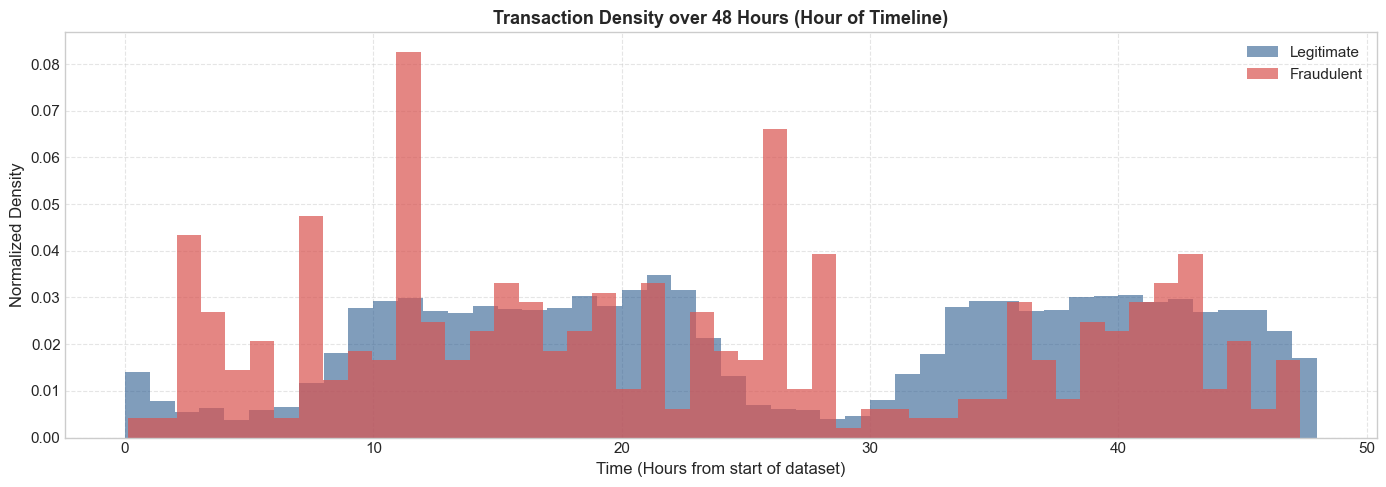

Observation: Legitimate transactions follow a distinct circadian rhythm (dip during night hours).
Fraud transactions exhibit a more continuous occurrence rate, even during low-volume night periods.
Recommendation: Engineer a cyclical 'Hour_of_Day' feature (Time % 86400 / 3600) in Phase 5.


In [11]:
# Time feature represents seconds elapsed from the first transaction over a 48-hour window (2 days)
total_hours = df['Time'].max() / 3600
print(f"Total time span covered: {df['Time'].max():,.1f} seconds (~{total_hours:.1f} hours / {total_hours / 24:.1f} days)")

fig, ax = plt.subplots(figsize=(14, 5))
ax.hist(df[df['Class'] == 0]['Time'] / 3600, bins=48, alpha=0.6, label='Legitimate', color='#2b5c8f', density=True)
ax.hist(df[df['Class'] == 1]['Time'] / 3600, bins=48, alpha=0.7, label='Fraudulent', color='#d9534f', density=True)

ax.set_title("Transaction Density over 48 Hours (Hour of Timeline)", fontweight='bold')
ax.set_xlabel("Time (Hours from start of dataset)")
ax.set_ylabel("Normalized Density")
ax.legend(loc='upper right')
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("Observation: Legitimate transactions follow a distinct circadian rhythm (dip during night hours).")
print("Fraud transactions exhibit a more continuous occurrence rate, even during low-volume night periods.")
print("Recommendation: Engineer a cyclical 'Hour_of_Day' feature (Time % 86400 / 3600) in Phase 5.")

## 6. Monetary Feature Analysis (`Amount`)

Transaction Amount Statistics by Class:
Class              0            1
count  284315.000000   492.000000
mean       88.291022   122.211321
std       250.105092   256.683288
min         0.000000     0.000000
25%         5.650000     1.000000
50%        22.000000     9.250000
75%        77.050000   105.890000
max     25691.160000  2125.870000


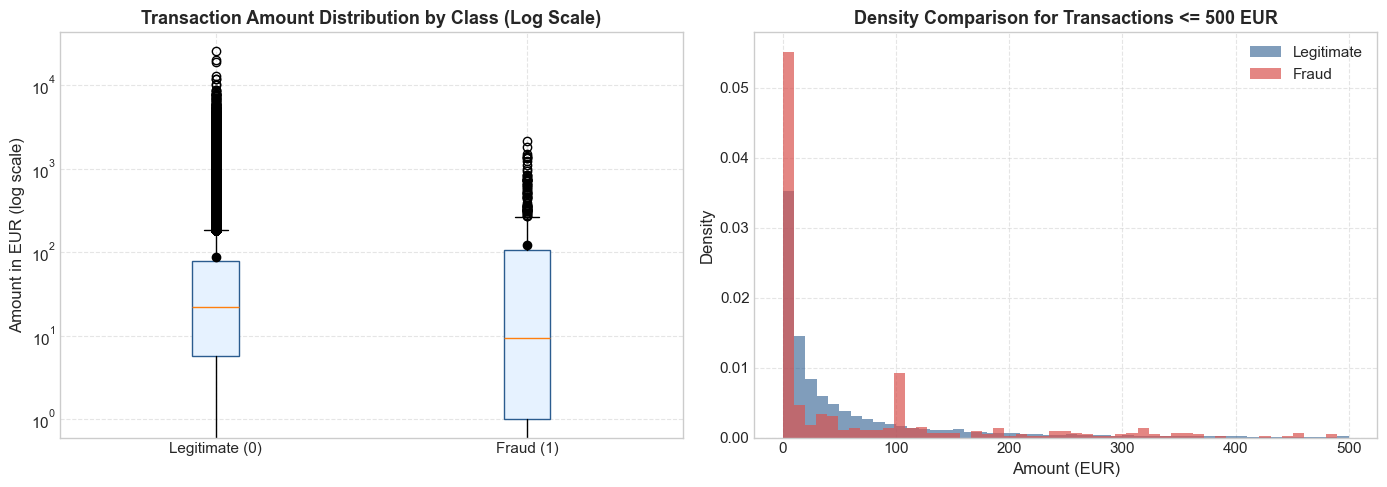

Observations:
1. Legitimate transactions range from 0.00 EUR to 25,691.16 EUR (Mean: 88.29, Median: 22.00).
2. Fraudulent transactions range from 0.00 EUR to 2,125.87 EUR (Mean: 122.21, Median: 9.25).
3. Fraud transactions have higher median amounts than legitimate transactions, but rarely reach extreme high values.
Recommendation: Apply log transformation (log1p) and RobustScaler to the Amount feature in Phase 5.


In [12]:
print("Transaction Amount Statistics by Class:")
amount_stats = df.groupby('Class')['Amount'].describe().T
print(amount_stats)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Boxplot of Transaction Amount by Class
boxplot_data = [df[df['Class'] == 0]['Amount'], df[df['Class'] == 1]['Amount']]
ax1.boxplot(boxplot_data, labels=['Legitimate (0)', 'Fraud (1)'], showmeans=True, patch_artist=True,
            boxprops=dict(facecolor='#e6f2ff', color='#2b5c8f'),
            meanprops=dict(marker='o', markeredgecolor='black', markerfacecolor='black'))
ax1.set_yscale('log')
ax1.set_title("Transaction Amount Distribution by Class (Log Scale)", fontweight='bold')
ax1.set_ylabel("Amount in EUR (log scale)")
ax1.grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Density comparison for Amount < 500
ax2.hist(df[(df['Class'] == 0) & (df['Amount'] <= 500)]['Amount'], bins=50, alpha=0.6, label='Legitimate', color='#2b5c8f', density=True)
ax2.hist(df[(df['Class'] == 1) & (df['Amount'] <= 500)]['Amount'], bins=50, alpha=0.7, label='Fraud', color='#d9534f', density=True)
ax2.set_title("Density Comparison for Transactions <= 500 EUR", fontweight='bold')
ax2.set_xlabel("Amount (EUR)")
ax2.set_ylabel("Density")
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("Observations:")
print(f"1. Legitimate transactions range from 0.00 EUR to {df[df['Class'] == 0]['Amount'].max():,.2f} EUR (Mean: {df[df['Class'] == 0]['Amount'].mean():.2f}, Median: {df[df['Class'] == 0]['Amount'].median():.2f}).")
print(f"2. Fraudulent transactions range from 0.00 EUR to {df[df['Class'] == 1]['Amount'].max():,.2f} EUR (Mean: {df[df['Class'] == 1]['Amount'].mean():.2f}, Median: {df[df['Class'] == 1]['Amount'].median():.2f}).")
print("3. Fraud transactions have higher median amounts than legitimate transactions, but rarely reach extreme high values.")
print("Recommendation: Apply log transformation (log1p) and RobustScaler to the Amount feature in Phase 5.")

## 7. Feature Correlation with Fraud Target

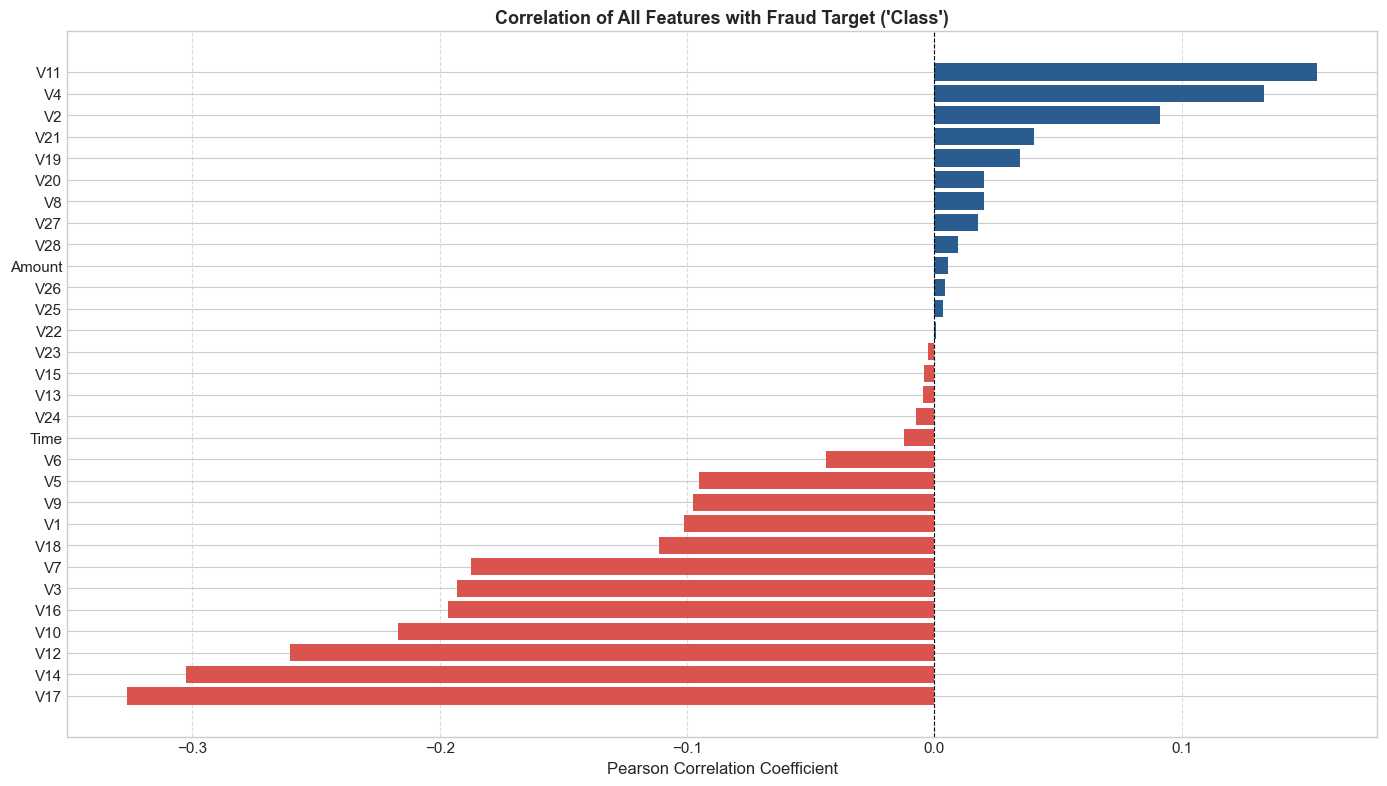

Top 5 Negatively Correlated Features with Fraud:
  V17     : -0.3265
  V14     : -0.3025
  V12     : -0.2606
  V10     : -0.2169
  V16     : -0.1965

Top 5 Positively Correlated Features with Fraud:
  V11     : +0.1549
  V4      : +0.1334
  V2      : +0.0913
  V21     : +0.0404
  V19     : +0.0348


In [13]:
# Compute Pearson correlation with Class
correlations = df.corr()['Class'].drop('Class').sort_values()

fig, ax = plt.subplots(figsize=(14, 8))
colors = ['#d9534f' if x < 0 else '#2b5c8f' for x in correlations]
bars = ax.barh(correlations.index, correlations.values, color=colors)

ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title("Correlation of All Features with Fraud Target ('Class')", fontweight='bold')
ax.set_xlabel("Pearson Correlation Coefficient")
ax.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

print("Top 5 Negatively Correlated Features with Fraud:")
for f, v in correlations.head(5).items():
    print(f"  {f:8s}: {v:+.4f}")

print("\nTop 5 Positively Correlated Features with Fraud:")
for f, v in correlations.tail(5).iloc[::-1].items():
    print(f"  {f:8s}: {v:+.4f}")

## 8. Key Discriminative PCA Features Comparison

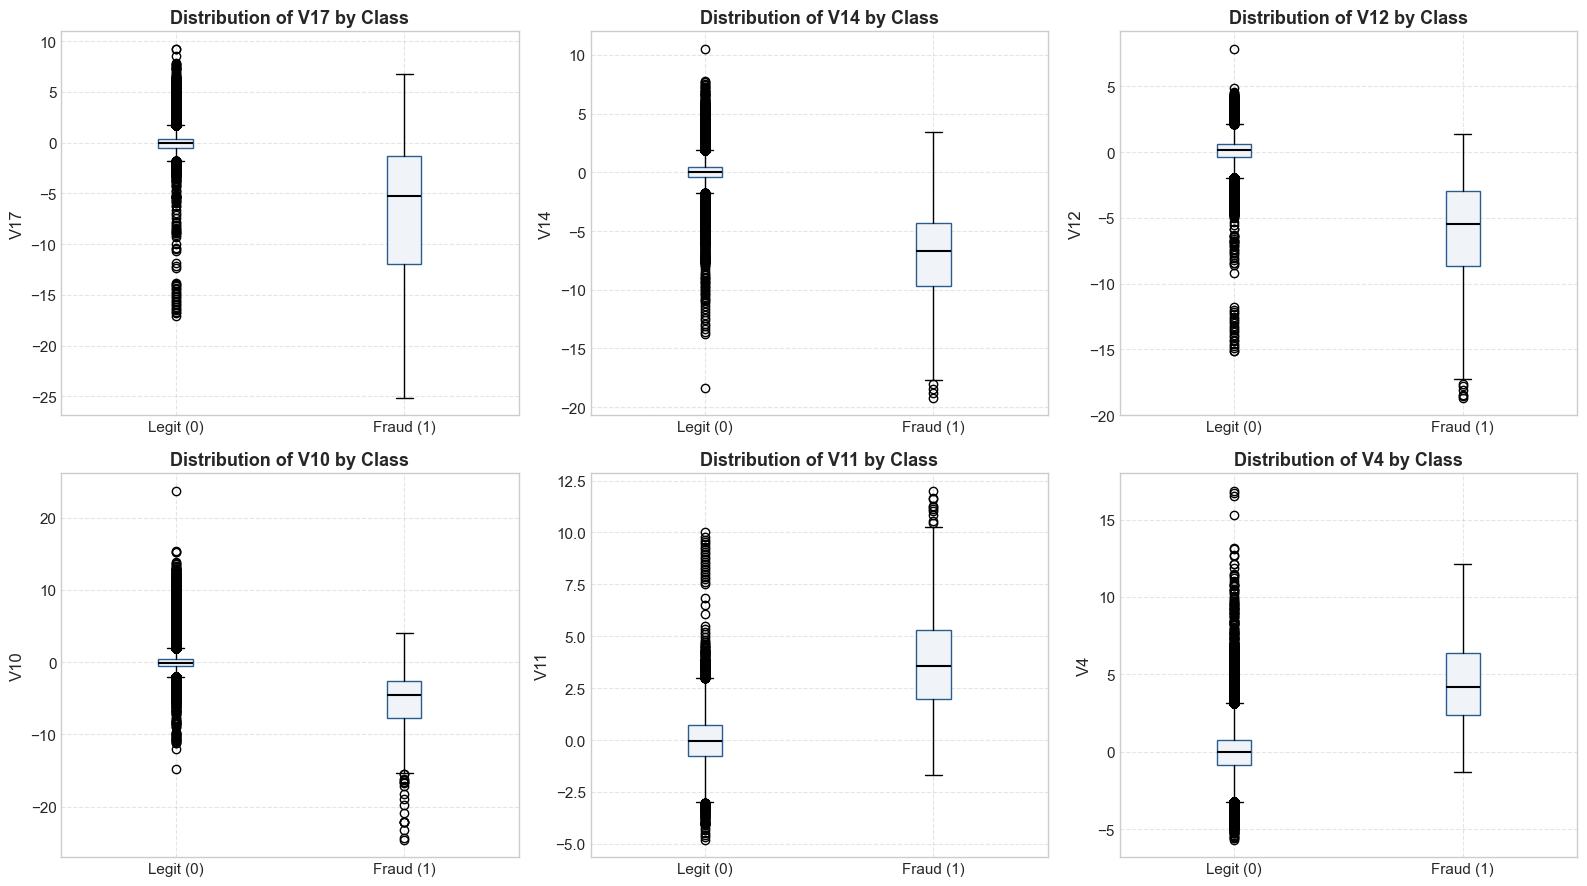

Observation: Features V17, V14, V12, and V10 show stark distribution shifts between legitimate and fraudulent transactions.
These features are expected to be strong drivers in XGBoost gradient boosting splits.


In [14]:
# Inspect distributions of top positive & negative discriminators
key_features = ['V17', 'V14', 'V12', 'V10', 'V11', 'V4']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, feat in enumerate(key_features):
    ax = axes[idx]
    ax.boxplot([df[df['Class'] == 0][feat], df[df['Class'] == 1][feat]],
                labels=['Legit (0)', 'Fraud (1)'],
                patch_artist=True,
                boxprops=dict(facecolor='#f0f4f8', color='#2b5c8f'),
                medianprops=dict(color='black', linewidth=1.5))
    ax.set_title(f"Distribution of {feat} by Class", fontweight='bold')
    ax.set_ylabel(feat)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("Observation: Features V17, V14, V12, and V10 show stark distribution shifts between legitimate and fraudulent transactions.")
print("These features are expected to be strong drivers in XGBoost gradient boosting splits.")

## 9. Comprehensive EDA Findings & Phase 5 Action Plan

### A. Key Dataset Insights
1. **Dimensions & Volume:** 284,807 transactions across 31 features (Time, Amount, V1–V28, Class).
2. **Missing Data:** **0 missing values** across the entire dataset.
3. **Severe Class Imbalance:** 
   - 284,315 legitimate transactions (99.827%)
   - 492 fraudulent transactions (0.173%)
   - Imbalance ratio: **577.88 : 1**
4. **Duplicates:** 1,081 duplicate transactions identified (1,062 legitimate, 19 fraudulent).
5. **Feature Representation:**
   - Features `V1`–`V28` are orthogonal continuous variables resulting from PCA.
   - `Time` and `Amount` are raw unscaled values.
   - `Time` spans 172,792 seconds (~48 hours) exhibiting diurnal periodicity.
   - `Amount` is highly skewed (mean: 88.35, median: 22.00, max: 25,691.16).

---

### B. Actionable Recommendations for Phase 5 (Preprocessing & Feature Engineering)

| Area | Challenge | Proposed Solution for Phase 5 |
| :--- | :--- | :--- |
| **Scaling** | `Amount` and `Time` have vastly different scales and severe outliers | Apply `RobustScaler` (resistant to outliers) to `Amount` and cyclical feature transformations. |
| **Feature Engineering** | Raw `Time` is monotonic rather than periodic | Create `Hour_of_Day = (Time % 86400) / 3600` and `Log_Amount = log1p(Amount)`. |
| **Class Imbalance** | Accuracy is a deceptive metric (a naive model achieves 99.83% accuracy) | 1. Use **Stratified K-Fold Cross-Validation**.<br>2. Configure `scale_pos_weight = 577.88` in XGBoost.<br>3. Optimize and evaluate using **PR-AUC (Precision-Recall AUC)** and **ROC-AUC** instead of accuracy. |
| **Data Leakage Prevention** | Scaler statistics computed on full dataset cause leakage | All scalers and encoders must be fit **strictly on training folds** within a cross-validation pipeline. |
| **Duplicate Handling** | Deduplication may remove valid burst transactions | Document policy and evaluate whether to retain or deduplicate in training splits. |